# Tiled shapes and their table (RFC 4) on the Atera kidney dataset

[RFC 4](https://spatialdata-spec.scverse.org/rfcs/0004-tiled-shapes.html) sorts the cells by the tile of their
centroid, on a grid of their own nested with the grid of the points, writes the geometry as GeoArrow, and stores the expression matrix as
CSR and CSC. This notebook adds this index to the cells of the store made in the points notebook
(`kidney_tiled.zarr`), reorders the table to the order of the cells, and reads cells and gene values by region.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import zarr

import spatialdata as sd
from spatialdata._io.spatial_index import PointsSpatialIndex, ShapesSpatialIndex, build_shapes_spatial_index

DATA = Path("/Users/macbook/embl/projects/basel/tiled-index-data")
OUT = DATA / "kidney.zarr"
sdata = sd.read_zarr(OUT)
sdata

/Users/macbook/embl/projects/basel/spatialdata-tiled-index/src/spatialdata/_core/spatialdata.py:173: UserWarning: The table is annotating 'cell_labels', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(table)


SpatialData object, with associated Zarr store: /Users/macbook/embl/projects/basel/tiled-index-data/kidney.zarr
├── Points
│     ├── 'transcripts_parquet': DataFrame with shape: (1186813834, 8) (3D points)
│     └── 'transcripts_zarr': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (399120, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (398197, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (399120, 24674)
with coordinate systems:
    ▸ 'global', with elements:
        transcripts_parquet (Points), transcripts_zarr (Points), cell_boundaries (Shapes), nucleus_boundaries (Shapes)

In [2]:
table = sdata["table"]
print(table)
print("layers already present in spatialdata-db:", list(table.layers))

AnnData object with n_obs × n_vars = 399120 × 24674
    obs: 'barcode', 'cell_id', 'filtered', 'leiden_res_1.0', 'centroid_column', 'centroid_row', 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'azimuth_broad', 'azimuth_coarse', 'azimuth_fine', 'azimuth_score', 'azimuth_full_hierarchy', 'label_id', 'n_genes', 'region'
    var: 'feature_name', 'filtered', 'highly_variable', 'feature_id', 'feature_types', 'genome', 'gene_ids'
    uns: 'spatialdata_attrs'
    obsm: 'X_umap', 'X_pca', 'spatial'
    layers: 'csc_counts', None (.X)
layers already present in spatialdata-db: ['csc_counts', None]


spatialdata-db already ships a CSC copy (`layers["csc_counts"]`); RFC 4 names it `X_csc`. The builder writes
`X_csc` (and leaves `csc_counts`) and reorders the rows of the table to the order of the cells. Its grid is nested
with the grid of the transcripts: a power of 2 times their tile size, the smallest one where more than half of the
cells lie within the tile of their centroid (RFC 4, "When to use it").

RFC 4 applies to a table that annotates the shapes. In this dataset the table annotates the cell *labels*
(`region="cell_labels"`, `instance_key="label_id"`), and the boundaries are matched through the column `cell_id`:
making the table annotate the boundaries is up to the user, done here first.

In [3]:
if "spatial_index" not in zarr.open_group(OUT / "shapes" / "cell_boundaries").attrs:
    # make the table annotate the cell boundaries (the user's responsibility, RFC 4)
    from spatialdata.models import TableModel

    t = sdata["table"]
    t.obs["region"] = pd.Categorical(["cell_boundaries"] * t.n_obs)
    t.uns[TableModel.ATTRS_KEY].update({"region": "cell_boundaries", "instance_key": "cell_id"})
    sdata.delete_element_from_disk("table")
    sdata.write_element("table")
    t0 = time.time()
    build_shapes_spatial_index(sdata, "cell_boundaries", table_name="table", nest_with_points="transcripts_parquet")
    print(f"{time.time() - t0:.0f} s")
index = ShapesSpatialIndex(OUT / "shapes" / "cell_boundaries", OUT / "tables" / "table")
print(index.metadata.levels[0], "margin", index.margin, "within tile", index.metadata.extra["fraction_within_tile"])

29 s
LevelGrid(origin=(-1.0, -2.0), tile_size=(56.810805015680856, 56.810805015680856), grid_shape=(212, 122), P=1.0) margin [30.77269985 21.88984857] within tile 0.7003006614552014


The grid is the one of the transcripts, so one tile request can load both. Note the margin: the largest overhang of
a cell outside its tile is about 30 um, 4-5 tiles of 6.7 um, so every box query is grown by that much (RFC 4 takes
the maximum over all the shapes; one large cell sets it for all).

In [4]:
pts = PointsSpatialIndex(OUT / "points" / "transcripts_parquet")
print(pts.metadata.levels[0].tile_size, index.metadata.levels[0].tile_size)

(28.405402507840428, 28.405402507840428, 21.0) (56.810805015680856, 56.810805015680856)


## Cells in view, colored by a gene read from the CSC layer

486 cells in 0.02 s, C7 in 0.04 s


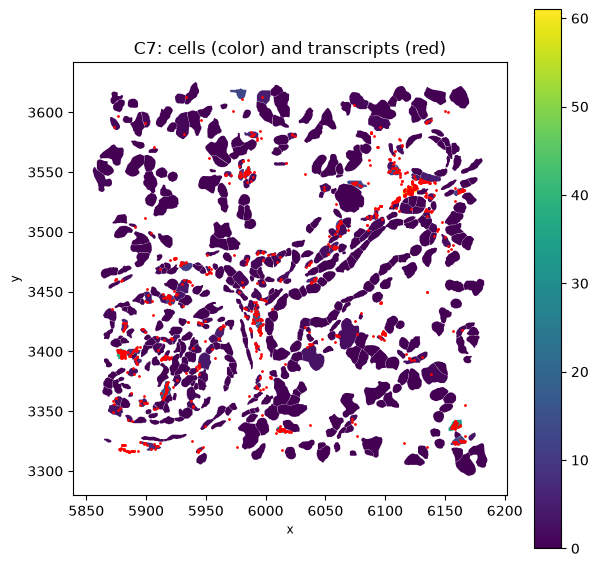

In [5]:
lv0 = index.metadata.levels[0]
center = np.array(lv0.origin) + np.array(lv0.tile_size) * np.array(lv0.grid_shape) / 2
lo, hi = center - 150, center + 150
gene = "C7"  # a gene expressed in kidney stroma
t0 = time.time()
cells = index.query(lo, hi)
t1 = time.time()
values = index.gene_values(gene, cells["__row__"].to_numpy())
t2 = time.time()
print(f"{len(cells)} cells in {t1 - t0:.2f} s, {gene} in {t2 - t1:.2f} s")
transcripts = pts.query(lo, hi, features=[gene], columns=["x", "y"])
ax = cells.plot(column=values, cmap="viridis", figsize=(7, 7), legend=True)
ax.scatter(transcripts.x, transcripts.y, s=1, c="red")
ax.set_title(f"{gene}: cells (color) and transcripts (red)")
plt.show()

## Zoomed out

RFC 4 has a single level for now: zoomed out, a client shows fewer cells by other means (aggregation, or the
transcripts alone). napari-spatialdata loads the cells only when at most `config.TILED_SHAPES_MAX` are in view.

## In napari

With the napari-spatialdata branch, the cell boundaries load by view when fewer than `config.TILED_SHAPES_MAX` cells
are in view, and `layer.metadata["_tiled_loader"].color_by_gene(gene)` colors them from the CSC layer.